In [ ]:
import os

def pastikan_file(nama):
    """Hentikan notebook dengan pesan jelas jika file input belum ada."""
    if not os.path.exists(nama):
        raise FileNotFoundError(
            f"File '{nama}' tidak ditemukan di folder {os.getcwd()}. "
            "Pastikan file ada di folder yang sama dengan notebook, "
            "atau jalankan progres sebelumnya terlebih dahulu.")

def unduh(*nama_file):
    """Di VS Code file sudah tersimpan di folder kerja; cukup tampilkan daftarnya."""
    for f in nama_file:
        print("Tersimpan:", os.path.abspath(f))

In [2]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)

In [3]:
pastikan_file("bphtb_bulanan.csv")
y = pd.read_csv("bphtb_bulanan.csv", index_col="bulan", parse_dates=True)["realisasi_miliar"].asfreq("MS")
print(len(y), "bulan:", y.index[0].strftime("%b %Y"), "–", y.index[-1].strftime("%b %Y"))

68 bulan: Jan 2021 – Aug 2026


In [4]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

## 3.1 Transformasi log
Jika simpangan baku per tahun ikut membesar bersama rata-ratanya, transformasi log membantu menstabilkan varians.

        mean   std
bulan             
2021   107.6  55.9
2022   106.7  57.1
2023   117.8  68.4
2024   111.8  59.9
2025   118.2  53.8
Korelasi rata-rata vs simpangan baku tahunan: 0.374


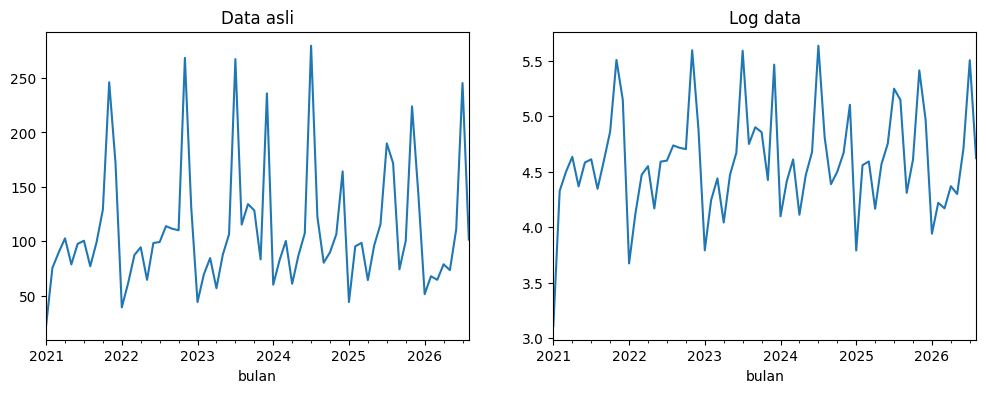

In [5]:
per_th = y[:"2025"].groupby(y[:"2025"].index.year).agg(["mean", "std"])
print(per_th.round(1))
print("Korelasi rata-rata vs simpangan baku tahunan:", round(per_th["mean"].corr(per_th["std"]), 3))
ly = np.log(y)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
y.plot(ax=ax[0], title="Data asli"); ly.plot(ax=ax[1], title="Log data"); plt.show()

## 3.2 Uji ADF dan KPSS
- **ADF**: H0 = ada akar unit (tidak stasioner). p < 0,05 → stasioner.
- **KPSS**: H0 = stasioner. p < 0,05 → tidak stasioner.

In [6]:
def uji_stasioner(seri, nama):
    seri = seri.dropna()
    adf_stat, p_adf, lag_adf, *_ = adfuller(seri, autolag="AIC")
    kpss_stat, p_kpss, *_ = kpss(seri, regression="c", nlags="auto")
    if p_adf < .05 and p_kpss >= .05:   kes = "Stasioner"
    elif p_adf >= .05 and p_kpss < .05: kes = "Tidak stasioner"
    else:                               kes = "Hasil uji tidak sepakat"
    return {"Seri": nama, "n": len(seri), "ADF stat": round(adf_stat, 3), "p ADF": round(p_adf, 4),
            "lag ADF": lag_adf, "KPSS stat": round(kpss_stat, 3), "p KPSS": round(p_kpss, 4), "Kesimpulan": kes}

hasil = pd.DataFrame([
    uji_stasioner(y, "Asli"),
    uji_stasioner(ly, "Log"),
    uji_stasioner(ly.diff(), "Log, d=1"),
    uji_stasioner(ly.diff(12), "Log, D=1 (s=12)"),
    uji_stasioner(ly.diff().diff(12), "Log, d=1 & D=1"),
])
hasil.to_csv("hasil_uji_stasioneritas.csv", index=False)
hasil

C:\Users\Athira R.F\AppData\Local\Temp\ipykernel_7356\1840425038.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_kpss, *_ = kpss(seri, regression="c", nlags="auto")
C:\Users\Athira R.F\AppData\Local\Temp\ipykernel_7356\1840425038.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_kpss, *_ = kpss(seri, regression="c", nlags="auto")
C:\Users\Athira R.F\AppData\Local\Temp\ipykernel_7356\1840425038.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_kpss, *_ = kpss(seri, regression="c", nlags="auto")


,Seri,n,ADF stat,p ADF,lag ADF,KPSS stat,p KPSS,Kesimpulan
0,Asli,68,-2.216,0.2007,11,0.100,0.1000,Hasil uji tidak sepakat
1,Log,68,-2.040,0.2692,11,0.133,0.1000,Hasil uji tidak sepakat
2,"Log, d=1",67,-6.847,0.0000,11,0.500,0.0417,Hasil uji tidak sepakat
3,"Log, D=1 (s=12)",56,-8.730,0.0000,0,0.129,0.1000,Stasioner
4,"Log, d=1 & D=1",55,-4.379,0.0003,9,0.500,0.0417,Hasil uji tidak sepakat


## 3.3 Stasioneritas musiman
ADF biasa tidak menguji akar unit musiman. Petunjuknya dilihat dari ACF di lag 12, 24, 36: jika tinggi dan meluruh lambat, perlu D = 1.

ACF log(y) di lag musiman: {12: 0.589, 24: 0.377, 36: 0.304}


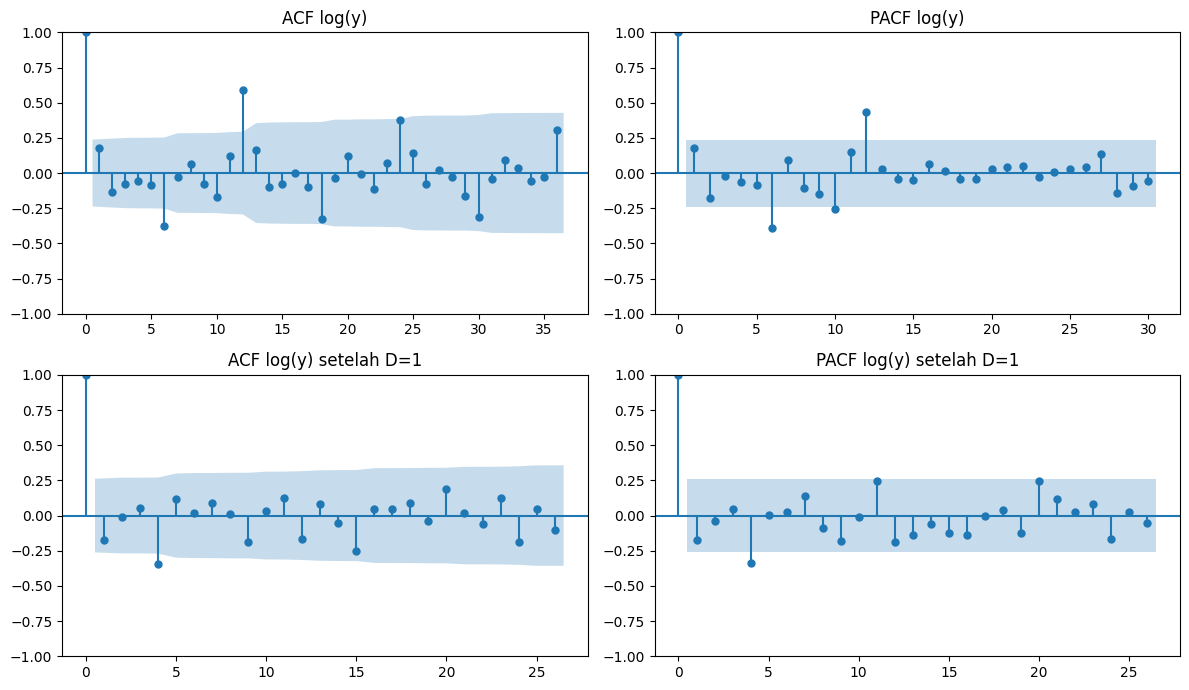

In [7]:
from statsmodels.tsa.stattools import acf
r = acf(ly, nlags=36)
print("ACF log(y) di lag musiman:", {k: round(r[k], 3) for k in (12, 24, 36)})

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(ly, lags=36, ax=ax[0, 0]); ax[0, 0].set_title("ACF log(y)")
plot_pacf(ly, lags=30, ax=ax[0, 1], method="ywm"); ax[0, 1].set_title("PACF log(y)")
w = ly.diff(12).dropna()
plot_acf(w, lags=26, ax=ax[1, 0]); ax[1, 0].set_title("ACF log(y) setelah D=1")
plot_pacf(w, lags=26, ax=ax[1, 1], method="ywm"); ax[1, 1].set_title("PACF log(y) setelah D=1")
plt.tight_layout(); plt.show()

## 3.4 Identifikasi orde awal SARIMA
Panduan membaca plot ACF/PACF setelah D = 1:
- **p (AR non-musiman):** PACF terpotong di lag 1–2.
- **q (MA non-musiman):** ACF terpotong di lag 1–2.
- **P (AR musiman):** PACF signifikan di lag 12.
- **Q (MA musiman):** ACF signifikan negatif di lag 12 (umum setelah diferensiasi musiman).

Dugaan awal yang dipakai di Progres 4: **SARIMA(p, 0, q)(P, 1, Q)₁₂ pada log(y)**, dengan p, q, P, Q ∈ {0, 1} dipilih berdasarkan AIC.

## 3.5 Pembagian data latih dan uji
12 bulan terakhir data riil dijadikan data uji agar setiap bulan kalender muncul tepat sekali.

In [8]:
AWAL_UJI = "2025-09-01"            # data uji: Sep 2025 – Agu 2026 (12 bulan)
train, test = y[y.index < AWAL_UJI], y[y.index >= AWAL_UJI]
print(len(train), "bulan latih |", len(test), "bulan uji")

56 bulan latih | 12 bulan uji


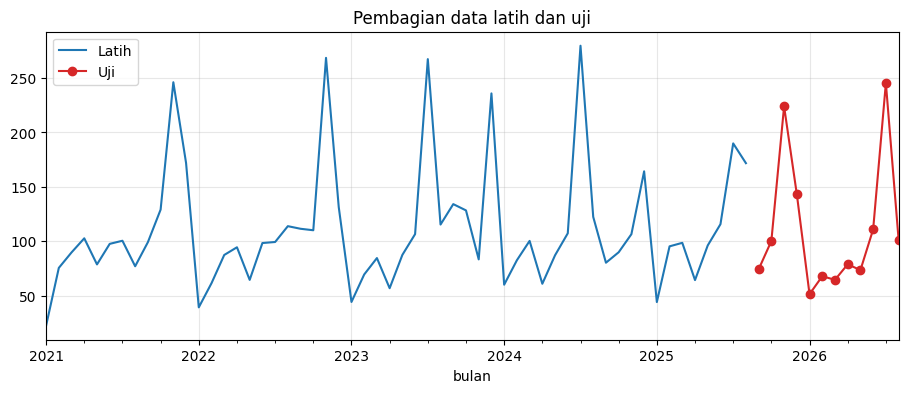

{'awal_uji': '2025-09-01', 'n_latih': 56, 'n_uji': 12, 'transformasi': 'log', 'd': 0, 'D': 1, 's': 12}
Tersimpan: c:\Users\Athira R.F\Documents\Python Programming\kuliah\magang\hasil_uji_stasioneritas.csv
Tersimpan: c:\Users\Athira R.F\Documents\Python Programming\kuliah\magang\pembagian_data.json


In [9]:
fig, ax = plt.subplots()
train.plot(ax=ax, label="Latih", color="tab:blue"); test.plot(ax=ax, label="Uji", color="tab:red", marker="o")
ax.set_title("Pembagian data latih dan uji"); ax.legend(); ax.grid(alpha=.3); plt.show()

pembagian = {"awal_uji": AWAL_UJI, "n_latih": len(train), "n_uji": len(test),
             "transformasi": "log", "d": 0, "D": 1, "s": 12}
json.dump(pembagian, open("pembagian_data.json", "w"), indent=2)
print(pembagian)
unduh("hasil_uji_stasioneritas.csv", "pembagian_data.json")